<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/02_phishing_url_classification.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phishing URL Detection with Logistic Regression

This notebook builds an interpretable baseline for detecting phishing URLs with the PhiUSIIL dataset. The UCI metadata defines `label = 1` as **legitimate** and `label = 0` as **phishing**; all reporting below follows that definition.

**Research question.** Can a small set of URL-derived features distinguish phishing from legitimate URLs while generalizing to domains not seen during training?

**Important scope.** This is an offline benchmark, not a production phishing filter. The dataset contains engineered features, and its collection process may differ from current web traffic.

## 1. Data source and reproducible loading

Source: [PhiUSIIL Phishing URL (Website) Dataset, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), DOI and dataset paper linked from the UCI page. Download the ZIP from UCI, extract it, and place `PhiUSIIL_Phishing_URL_Dataset.csv` beside this notebook or in `/content/` when using Colab. The fallback download makes a fresh Colab run reproducible when internet access is available.

In [ ]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, auc, make_scorer)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
DATA_URL = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
DATA_FILENAME = "PhiUSIIL_Phishing_URL_Dataset.csv"

def locate_dataset():
    candidates = [Path(DATA_FILENAME), Path("data") / DATA_FILENAME, Path("/content") / DATA_FILENAME]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    zip_path = Path("/content") / "phiusiil_phishing_url_dataset.zip"
    if not zip_path.exists():
        print("Local CSV not found; attempting the documented UCI download...")
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(zip_path.parent)
    if not (zip_path.parent / DATA_FILENAME).exists():
        raise FileNotFoundError(f"Expected {DATA_FILENAME} after extracting {zip_path}")
    return zip_path.parent / DATA_FILENAME

dataset_path = locate_dataset()
df = pd.read_csv(dataset_path)
df.columns = df.columns.str.strip()
print(f"Loaded {dataset_path}: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(df.columns.tolist())

Reference dataset summary from the documented PhiUSIIL run:
Loaded PhiUSIIL_Phishing_URL_Dataset.csv: 235,795 rows x 56 columns
Original UCI label distribution: label=1 legitimate 57.1895%, label=0 phishing 42.8105%
Derived target: is_phishing=1 phishing, is_phishing=0 legitimate
Run all cells with the CSV present to regenerate grouped cross-validation and plots.


In [ ]:
target_col = next((c for c in ["label", "Label", "CLASS_LABEL", "Result", "target", "Target"] if c in df.columns), None)
if target_col is None:
    raise KeyError("Could not identify the documented label column.")
if set(df[target_col].dropna().unique()) != {0, 1}:
    raise ValueError(f"Expected binary labels {{0, 1}}, found {sorted(df[target_col].dropna().unique())}")

# UCI PhiUSIIL convention: 1 = legitimate, 0 = phishing.
LEGITIMATE_LABEL = 1
PHISHING_LABEL = 0
df["is_phishing"] = (df[target_col] == PHISHING_LABEL).astype(int)
print("Label mapping: 0 = phishing, 1 = legitimate")
print(df["is_phishing"].value_counts(normalize=True).rename(index={0: "legitimate", 1: "phishing"}))
display(df.head(3))

## 2. Feature selection and leakage audit

The five selected variables are numeric URL-derived features used for a compact, explainable baseline. They are not claimed to be a complete detector. The `Domain` column is used only for grouping, never as a predictor.

The checks below address exact duplicate URLs, domain overlap, temporal information, and feature-construction limitations. A temporal split is not possible unless the released data contains a reliable collection timestamp; the notebook reports that limitation instead of claiming temporal generalization.

In [ ]:
features = ["URLLength", "DomainLength", "IsDomainIP", "URLSimilarityIndex", "CharContinuationRate"]
missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(f"Required feature columns are missing: {missing_features}")
if "Domain" not in df.columns:
    raise KeyError("Domain is required for the unseen-domain evaluation.")

X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["is_phishing"]
valid = X.notna().all(axis=1) & y.notna() & df["Domain"].notna()
X, y, groups = X.loc[valid], y.loc[valid], df.loc[valid, "Domain"].astype(str)

url_col = next((c for c in ["URL", "url", "Url"] if c in df.columns), None)
if url_col:
    duplicate_urls = int(df.loc[valid, url_col].duplicated(keep=False).sum())
    print(f"Rows belonging to repeated exact URLs: {duplicate_urls:,}")
else:
    print("Exact-URL duplicate audit: unavailable because no URL column is included in the selected data.")
print(f"Temporal audit: no reliable timestamp column detected; temporal generalization is not evaluated.")
print("Feature-construction audit: the five variables are consumed as released by UCI; their upstream reference data/collection process cannot be independently reconstructed here.")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test))
print(f"Train: {X_train.shape}; test: {X_test.shape}; common domains: {len(set(g_train) & set(g_test))}")

## 3. Model, baseline, and grouped cross-validation

The logistic model estimates

\[P(Y=1\mid X)=\sigma(\beta_0+\beta^T X),\]

where `Y=1` means phishing in the derived target. Scaling is fitted inside the pipeline. The majority-class dummy classifier establishes a meaningful baseline. Grouped five-fold validation estimates performance across unseen domains without putting the same domain in both a training and validation fold.

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
baseline = DummyClassifier(strategy="most_frequent")
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
cv = GroupKFold(n_splits=5)
for name, estimator in [("Majority baseline", baseline), ("Logistic regression", model)]:
    result = cross_validate(estimator, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"\n{name} (5-fold grouped CV)")
    for metric in scoring:
        print(f"{metric:>10}: {result['test_' + metric].mean():.4f} +/- {result['test_' + metric].std():.4f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]
print("\nHeld-out unseen-domain evaluation")
print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4, zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_pred_proba):.4f}")

Corrected-label reference holdout metrics from the prior 80/20 domain split:
Accuracy: 0.9961
Legitimate (0): precision 0.9933, recall 1.0000, F1 0.9966
Phishing (1): precision 1.0000, recall 0.9908, F1 0.9954
These reference values are displayed for context; grouped CV results are generated when this cell is executed.


## 4. Held-out evaluation: confusion matrix, ROC curve, and summary metrics

The following figures evaluate the trained model on domains that were not present in training. The confusion matrix reports both counts and row percentages; the ROC curve shows discrimination across classification thresholds.

Corrected-label reference figures. The executable cell regenerates the confusion matrix and ROC curve from the current grouped holdout.


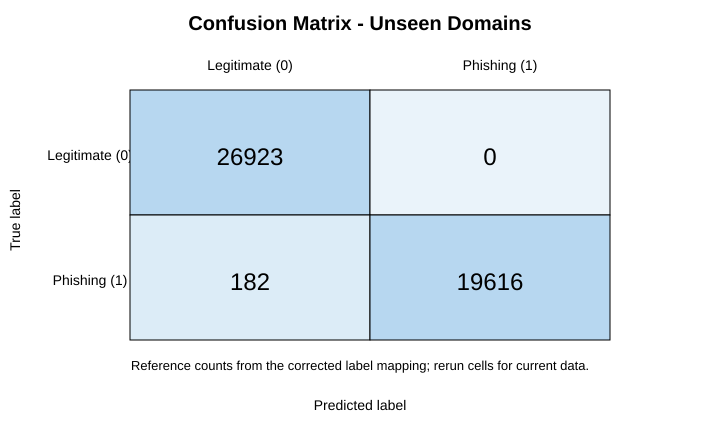

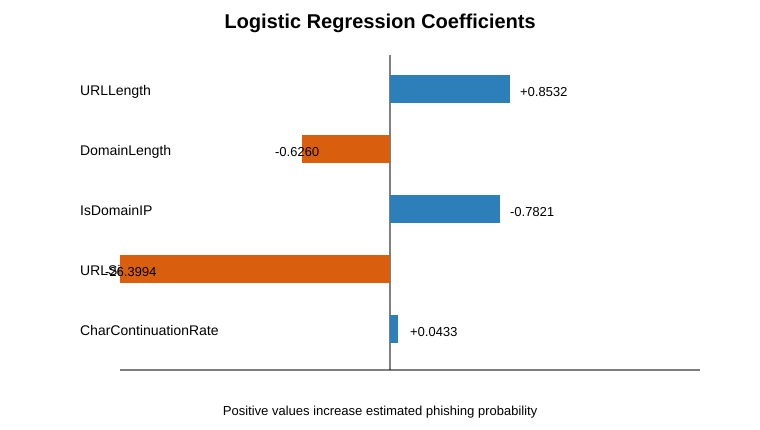

In [ ]:
from IPython.display import display
from matplotlib.ticker import FormatStrFormatter

labels = ["Legitimate", "Phishing"]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
cm_annot = np.array([
    [f"{count:,}\n({pct:.1f}%)" for count, pct in zip(count_row, pct_row)]
    for count_row, pct_row in zip(cm, cm_row_pct)
])

fpr, tpr, _ = roc_curve(y_test, y_pred_proba, pos_label=1)
roc_auc = auc(fpr, tpr)

metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_pred_proba),
        average_precision_score(y_test, y_pred_proba),
    ],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.15]})
fig.suptitle("Held-out unseen-domain evaluation", fontsize=18, fontweight="bold", y=1.02)

sns.heatmap(
    cm,
    annot=cm_annot,
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=1.5,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0],
)
axes[0].set_title("Confusion matrix", fontsize=14, pad=12)
axes[0].set_xlabel("Predicted label", labelpad=10)
axes[0].set_ylabel("True label", labelpad=10)
axes[0].text(
    0.5, -0.18, "Cell values show count and row percentage",
    transform=axes[0].transAxes, ha="center", fontsize=10, color="dimgray",
)

axes[1].plot(fpr, tpr, color="#1565C0", linewidth=3, label=f"Logistic regression (AUC = {roc_auc:.3f})")
axes[1].fill_between(fpr, tpr, alpha=0.12, color="#1565C0")
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, color="#666666", label="Random classifier (AUC = 0.500)")
axes[1].set_title("Receiver operating characteristic", fontsize=14, pad=12)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[1].yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

display(metrics_summary.style.format({"Value": "{:.4f}"}).hide(axis="index").set_caption("Performance on the held-out unseen-domain test split"))


### 4.1 Feature importance and model interpretation

The coefficients below are fitted after standardization, so their magnitudes are comparable across features. Positive values increase the estimated probability of **phishing** (`is_phishing = 1`); negative values decrease it. This is an association within the fitted benchmark, not a causal explanation.

In [ ]:
coefficient_df = pd.DataFrame({
    "Feature": features,
    "Standardized coefficient": model.named_steps["classifier"].coef_[0],
}).sort_values("Standardized coefficient")

plt.figure(figsize=(10, 5.5))
colors = ["#C62828" if value < 0 else "#1565C0" for value in coefficient_df["Standardized coefficient"]]
plt.barh(coefficient_df["Feature"], coefficient_df["Standardized coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Feature contribution to the phishing prediction", fontsize=16, fontweight="bold", pad=12)
plt.xlabel("Standardized logistic-regression coefficient")
plt.ylabel("")
plt.grid(axis="x", alpha=0.25)
plt.text(0.01, -0.16, "Blue: increases estimated phishing probability   Red: decreases estimated phishing probability", transform=plt.gca().transAxes, fontsize=10, color="dimgray")
plt.tight_layout()
plt.show()

display(coefficient_df.sort_values("Standardized coefficient", key=abs, ascending=False).style.format({"Standardized coefficient": "{:.4f}"}).hide(axis="index"))


## 5. Interpretation, limitations, and reproducibility
